T. J.-Y. Derrien <derrien@fzu.cz>

# Accounting for the effect of CEP or not?

In [2]:
from octopus_slabs.Pulses.libPulseGenerator import NonChirpedGaussianPulse
import numpy as np
from scipy.constants import h, c, e, pi, hbar

In [43]:
# tau=25e-15; wavelength=650e-9 #ORPHEUS-F dual pulse
# tau=100e-15; wavelength=2500e-9 #ORPHEUS-F dual pulse
# tau=30e-15; wavelength=800e-9 #Astrella
# tau=250e-15; wavelength=1030e-9 #Light Conversion, Pharos
# tau_exp=10.5e-15; wavelength_exp=2000e-9 #Martin Kozak experiments
# tau_exp=10.3E-15; wavelength_exp=3200e-9 #PRL/PRX main pulse
tau_exp=1.03071305416229e-14; wavelength_exp=1030E-9 #Excitation rate for Pharos
# tau_exp=5.15356527081145e-15; wavelength_exp=515E-9 #Excitation rate for Pharos 2nd harmonic

# Material parameters
Egap_LDA=2.56*e
Egap_exp=3.4*e #ambient temperature

# Number of cycles in the experiment
omega=2*pi*c/wavelength_exp
DurationOfOneCycle=2*pi/omega
NumberOfCycles=2*tau_exp/DurationOfOneCycle

# Deducing the required equivalent for TDDFT simulation
photon_energy_exp= hbar * omega #exp
# We need: Elaser/EgapExp = photon_energy_simulation/EgapLDA
photon_energy_simulation = photon_energy_exp / Egap_exp * Egap_LDA
wavelength_simulation = h * c / photon_energy_simulation
# Number of cycles in the simulation
omega_simulation=2*pi*c/wavelength_simulation
DurationOfOneCycle_simulation=2*pi/omega_simulation
# NumberOfCycles_simulation=2*tau_simulation/DurationOfOneCycle_simulation
tau_simulation = NumberOfCycles/2*DurationOfOneCycle_simulation

## SELECTING SIMULATION DATA
# tau = tau_simulation
# wavelength = wavelength_simulation

## SELECTING EXPERIMENTAL DATA
tau = tau_exp
wavelength = wavelength_exp

print("Wavelength for experiment:  "+str(1E9*wavelength_exp)+" nm")
print("Pulse duration for experiment:  "+str(1E15*tau_exp)+" fs")
print("")
print("Wavelength for computation: "+str(1E9*wavelength_simulation)+" nm")
print("Pulse duration for computation:  "+str(1E15*tau_simulation)+" fs")
print("")
print("Chosen wavelength for drawing: "+str(1E9*wavelength)+" nm")
print("Chosen pulse duration for drawing: "+str(1E15*tau)+" fs")


Wavelength for experiment:  1030.0 nm
Pulse duration for experiment:  10.3071305416229 fs

Wavelength for computation: 1367.9687499999998 nm
Pulse duration for computation:  13.689157750592909 fs

Chosen wavelength for drawing: 1030.0 nm
Chosen pulse duration for drawing: 10.3071305416229 fs


In [44]:
t=np.linspace(0,4*tau,500)
amplitude=3E9
phase=0.
duration=tau
polarization=0e0
delay=2*tau
pulse=NonChirpedGaussianPulse(t, amplitude, wavelength, phase, duration, polarization, delay)

5.999999999999999


/home/hilase/.conda/envs/python3clean/lib/python3.7/site-packages/numpy/core/_asarray.py:83: ComplexWarning: Casting complex values to real discards the imaginary part
  return array(a, dtype, copy=False, order=order)


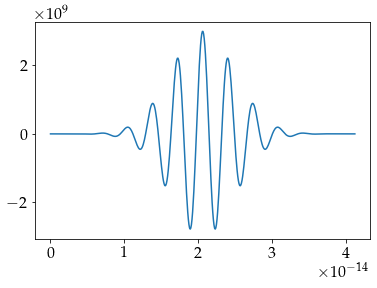

In [45]:
import matplotlib.pyplot as plt
plt.figure()
plt.plot(t, pulse)
print(NumberOfCycles)

In [57]:
3*2*pi/omega

1.03071305416229e-14